In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label

In [2]:
#Defining all the required functions

#Fourier Transform Functions
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

In [3]:
# List of simulation directories
sim_dirs = [
    '/DATA/DEVESH/ResistivityCheck/0.625e-4',
    '/DATA/DEVESH/ResistivityCheck/1.25e-4',
    '/DATA/DEVESH/ResistivityCheck/2.5e-4_2048',
    '/DATA/DEVESH/ResistivityCheck/5e-4'
]

dx = 0.0625
dy = 0.0625

In [40]:
#Lets Computer J_total

i = 42
sim_dir = sim_dirs[0]
# 1. Read the HDF5 file
File_Bx = f'{sim_dir}/Bx_ApJ_t{i}.h5'  
File_By = f'{sim_dir}/By_ApJ_t{i}.h5'  
File_Bz = f'{sim_dir}/Bz_ApJ_t{i}.h5'  

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Jx = partial_y_fft(data_Bz,dx)
    data_Jy = -partial_x_fft(data_Bz,dy)
    data_Jz = partial_x_fft(data_By,dy)-partial_y_fft(data_Bx,dx)

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2

#Different Strategies for Threshold
#Strategy 1: Pick top 10% of the features
# threshold = np.quantile(J_squared, 0.7)
threshold = 0.04548787954719731

#Strategy 2: 
# N = 3
# J_squared_rms = np.sqrt(np.mean(J_squared**2))
# threshold = np.mean(J_squared) + N*J_squared_rms

print("Threshold:", threshold)

binary_mask = np.abs(J_squared) > threshold


#MORPHOLOGICAL SMOOTHING
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

#Remove small areas
min_area = 100 # choose based on eye balling
cleaned_mask = morphology.remove_small_objects(smoothed_mask.astype(bool), min_size=min_area).astype(int)

Threshold: 0.04548787954719731


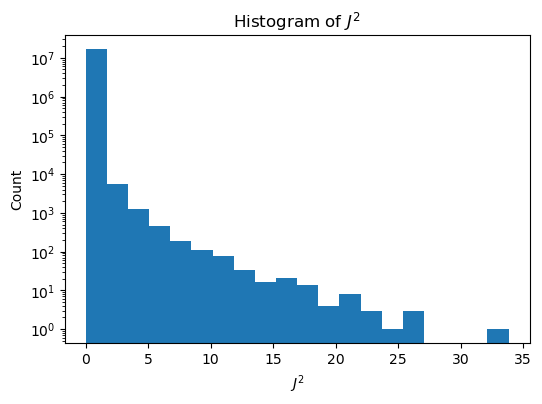

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten to 1D for histogram
J_flat = J_squared.ravel()

plt.figure(figsize=(6, 4))
plt.hist(J_flat, bins=20, log=True)  # log scale helps for heavy tails
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title('Histogram of $J^2$')
plt.show()

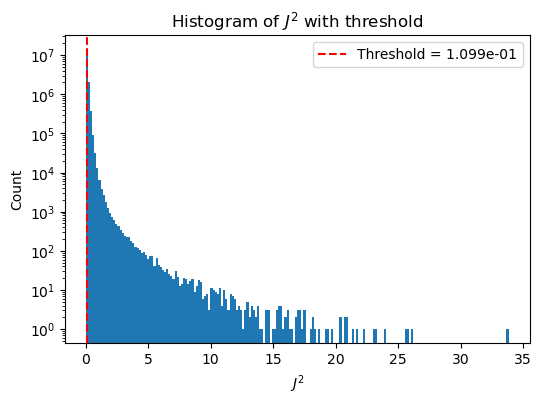

In [38]:
threshold = np.quantile(J_squared, 0.7)

plt.figure(figsize=(6, 4))
plt.hist(J_flat, bins=200, log=True)
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold = {threshold:.3e}')
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title('Histogram of $J^2$ with threshold')
plt.legend()
plt.show()

In [39]:
from skimage.filters import threshold_otsu

logJ = np.log10(J_squared[J_squared > 0])
t_log = threshold_otsu(logJ)

t = 10**t_log  # convert back to linear space
print("Otsu threshold:", t)

Otsu threshold: 0.04548787954719731


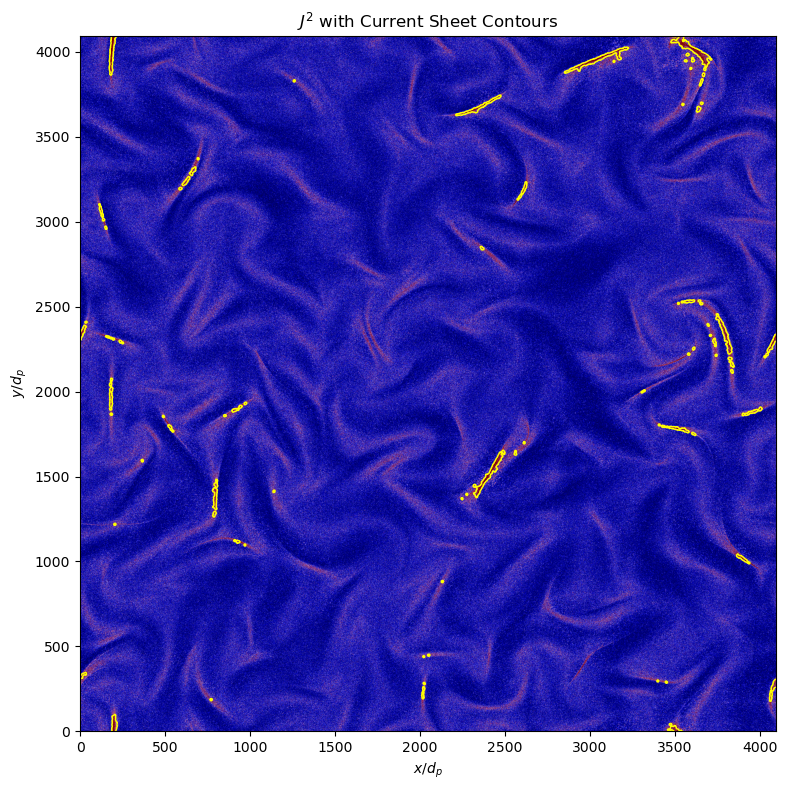

In [41]:
#Plot current sheets over the base J_squared field

plt.figure(figsize=(10, 8))

# Base field
plt.imshow(J_squared.T, cmap='seismic', origin='lower', vmax = 0.5)

# Add current-sheet boundaries
plt.contour(cleaned_mask.T, levels=[0.5], colors='yellow', linewidths=1)

plt.title(r'$J^{2}$ with Current Sheet Contours')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.savefig("J2_with_CS_contours.png", dpi=300)
plt.show()

In [35]:
#FIND MAXIMUM IN EACH CONNECTED REGION

labeled_mask, num_features = label(cleaned_mask)
print("Regions found:", num_features)

# max_coords = []
# max_values = []

# for i in range(1, num_features + 1):
#     region_mask = (labeled_mask == i)
#     region_vals = J_squared[region_mask]

#     if region_vals.size == 0:
#         continue

#     # Extreme value (max magnitude)
#     max_pos = np.argmax(np.abs(region_vals))
#     extreme_value = region_vals[max_pos]
#     max_values.append(extreme_value)

#     # Convert index → coordinates
#     xs, ys = np.where(region_mask)
#     max_coords.append((xs[max_pos], ys[max_pos]))

Regions found: 26


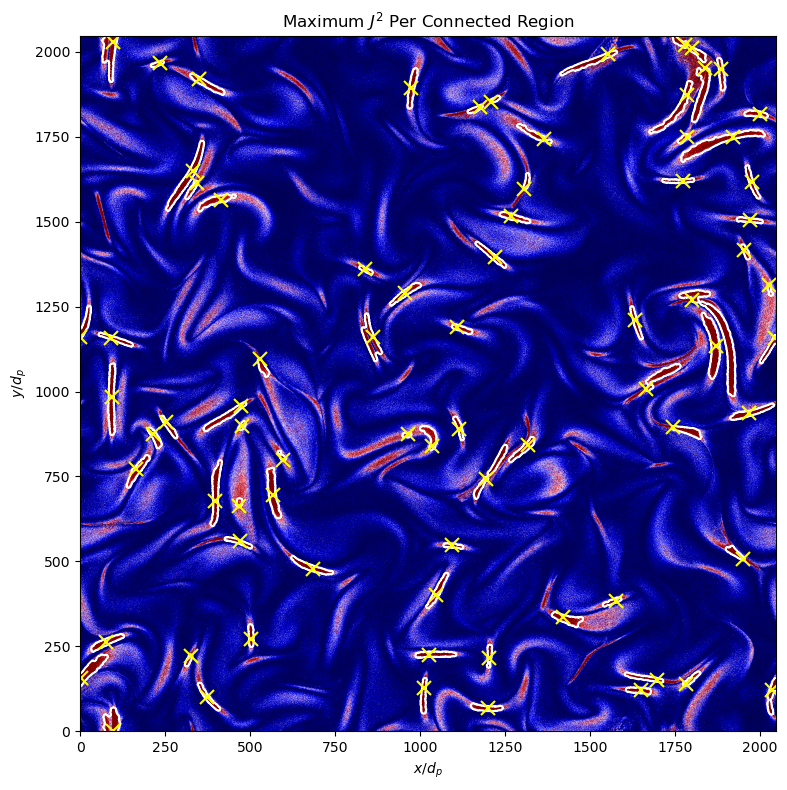

In [11]:
# PLOT ORIGINAL FIELD + MASK + MAXIMUM POINTS

plt.figure(figsize=(10, 8))

# --- Base field ---
plt.imshow(J_squared.T, cmap='seismic', origin='lower', vmax=0.05)

# --- Boundaries of CSs---
boundaries = find_boundaries(labeled_mask)
plt.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)

# --- Overlay maxima as yellow crosses ---
for x, y in max_coords:
    plt.plot(x, y, marker='x', markersize=10, markeredgewidth=1.5, color='yellow')

plt.title(r'Maximum $J^{2}$ Per Connected Region')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("J2_maxima_overlay.png", dpi=300)
plt.show()

In [12]:
# Compute gradient of J_squared
dJdx, dJdy = np.gradient(J_squared)  # assumes unit grid spacing

descent_dirs = []  # (dx, dy) unit vectors

for (x, y) in max_coords:
    gx = dJdx[x, y]
    gy = dJdy[x, y]

    grad = np.array([gx, gy])

    # Avoid division by zero
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
        continue

    # Direction of steepest descent = negative normalized gradient
    descent = -grad / np.linalg.norm(grad)
    descent_dirs.append(descent)

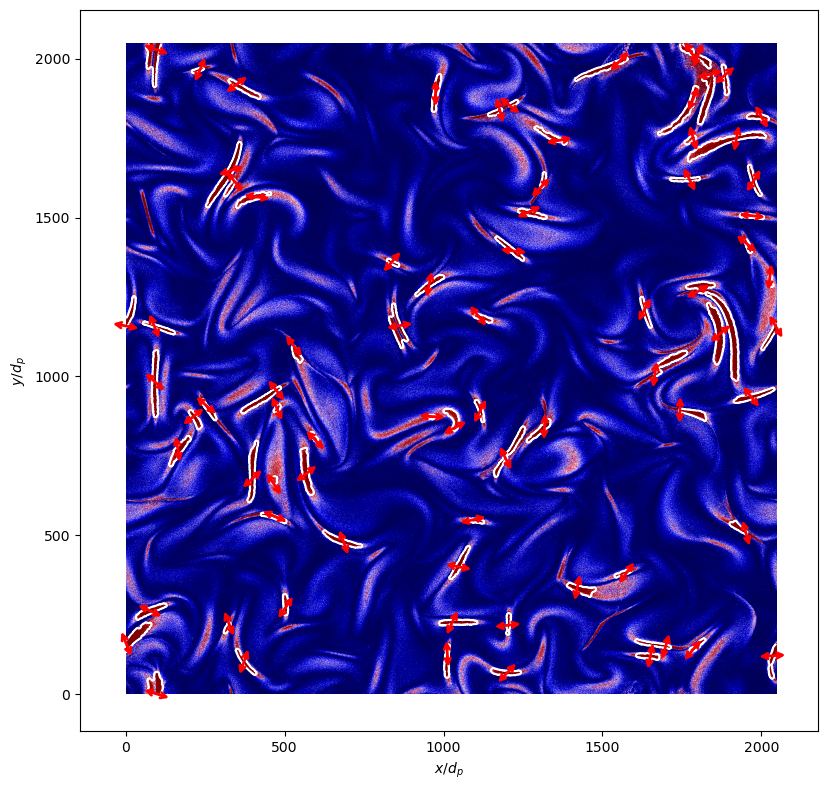

In [13]:
# Plotting the steepest descent direction
fig, ax = plt.subplots(figsize=(10, 8))

# --- Base field image ---
ax.imshow(J_squared.T, cmap='seismic', origin='lower', vmax=0.05, aspect='equal', zorder=0)

# --- Boundaries of connected structures ---
boundaries = find_boundaries(labeled_mask)
ax.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1, zorder=2)

# --- Arrows for maxima (always on top) ---
factor = 100.0
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):

    start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
    end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)

    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="<->",
        color="red",
        mutation_scale=10,
        linewidth=2,
        zorder=10             
    )
    ax.add_patch(arrow)

# --- Axis labels & title ---
ax.set_title(r'')
ax.set_xlabel(r'$x/d_p$')
ax.set_ylabel(r'$y/d_p$')

# --- Save clean figure ---
plt.tight_layout()
plt.savefig("J2_Descent_Direction.png", dpi=300)
plt.show()

In [14]:
# Method 3: Thickness = FWHMs

# ---------- Gaussian model ----------
def gaussian(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

# ---------- Parameters ----------
max_len = 60  # half-length of profile
step_px = 1   # pixel step along line

# ---------- Storage ----------
fwhms = []
xs_list = []
vals_list = []
popts_list = []

# ---------- Main loop ----------
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):

    # Skip zero vector directions
    if dx == 0 and dy == 0:
        fwhms.append(np.nan)
        xs_list.append(np.array([]))
        vals_list.append(np.array([]))
        popts_list.append([np.nan, np.nan, np.nan, np.nan])
        continue

    xs = []
    vals = []

    # Sample integer pixels along the line
    for k in range(-max_len, max_len + 1):
        xc = x + k * dx
        yc = y + k * dy
        xi = int(round(xc))
        yi = int(round(yc))

        if 0 <= xi < J_squared.shape[0] and 0 <= yi < J_squared.shape[1]:
            xs.append(k)
            vals.append(J_squared[xi, yi])
        else:
            continue  # skip out-of-bounds points

    xs = np.array(xs)
    vals = np.array(vals)

    xs_list.append(xs)
    vals_list.append(vals)

    # Handle empty or too-short profiles
    if len(vals) < 3:
        fwhms.append(np.nan)
        popts_list.append([np.nan, np.nan, np.nan, np.nan])
        continue

    # Initial Gaussian guess
    A0 = vals.max() - vals.min()
    mu0 = xs[np.argmax(vals)]
    sigma0 = max_len / 4
    B0 = vals.min()

    try:
        popt, pcov = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
        A, mu, sigma, B = popt
        fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma

        fwhms.append(fwhm)
        popts_list.append(popt)
    except RuntimeError:
        fwhms.append(np.nan)
        popts_list.append([np.nan, np.nan, np.nan, np.nan])

In [15]:
# Save all the fits to a folder
save_folder = "gaussian_fits_J2"
os.makedirs(save_folder, exist_ok=True)

# ---------- Plot and save all fits ----------
for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):

    if len(xs) == 0 or np.isnan(popt[0]):
        continue  # skip empty profiles or failed fits

    A, mu, sigma, B = popt
    x_dense = np.linspace(xs.min(), xs.max(), 500)
    fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma**2)) + B

    plt.figure()
    plt.plot(xs, vals, 'o', label="sampled profile")
    plt.plot(x_dense, fit_curve, label="Gaussian fit")
    plt.title(f"Sample {i} — FWHM = {fwhm:.2f} px")
    plt.xlabel("t (pixels)")
    plt.ylabel("Intensity")
    plt.legend()

    # Save figure
    filename = os.path.join(save_folder, f"fit_{i:03d}.png")
    plt.savefig(filename)
    plt.close()

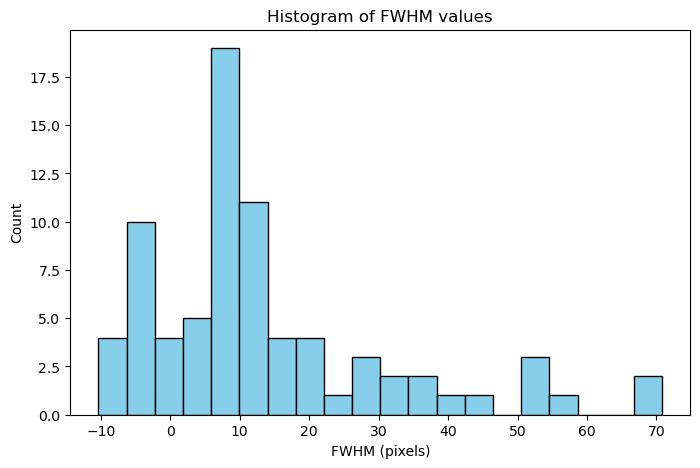

In [16]:
# Convert to numpy array and remove NaNs
fwhms_array = np.array(fwhms)
thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]

plt.figure(figsize=(8, 5))
plt.hist(thicknesses_m3, bins=20, color='skyblue', edgecolor='k')
plt.title("Histogram of FWHM values")
plt.xlabel("FWHM (pixels)")
plt.ylabel("Count")
plt.savefig("J2_M3_Histogram.png", dpi=300)
plt.show()

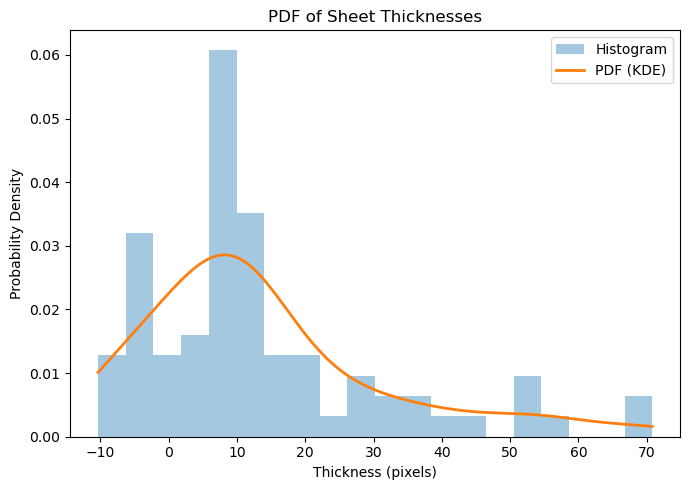

In [17]:
#Plot a smooth PDF of the same data
plt.figure(figsize=(7,5))

# Histogram (normalized)
plt.hist(thicknesses_m3, bins=20, density=True, alpha=0.4, label="Histogram")

# KDE curve
kde = gaussian_kde(thicknesses_m3)
xs = np.linspace(min(thicknesses_m3), max(thicknesses_m3), 500)
plt.plot(xs, kde(xs), linewidth=2, label="PDF (KDE)")
plt.xlabel("Thickness (pixels)")
plt.ylabel("Probability Density")
plt.title("PDF of Sheet Thicknesses")
plt.legend()
plt.tight_layout()
plt.savefig("J2_M3_PDF.png", dpi=300)
plt.show()